# Practice: The Full NLP Pipeline (Tokens → Embeddings → Pooling → PCA Projection)

Let's practice the process of tokenization, embedding, pooling, and projection. We use simple text sentences. Then we will use ESM-2, a model that process protein sequences.

1. **Imports** the tools we need: PyTorch (the neural-network engine), NumPy/pandas (data), matplotlib (plots), scikit-learn's PCA, and the Hugging Face `transformers` loaders.
2. **Downloads a small pretrained text model** (`all-MiniLM-L6-v2`) plus its tokenizer, and puts it in `eval()` mode so it only does inference (no training).


In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoTokenizer, AutoModel

# 1. We will use a small pre-trained text transformer
text_model_name = 'sentence-transformers/all-MiniLM-L6-v2'
text_tokenizer = AutoTokenizer.from_pretrained(text_model_name)
text_model = AutoModel.from_pretrained(text_model_name)
text_model.eval()

# 2. Define our practice sentences belonging to 3 distinct 'families' of topics
practice_data = [
    ("Science", "Gravity pulls objects together in space."),
    ("Science", "Light traveling from stars takes billions of years."),
    ("Science", "Electrons orbit the nucleus of an atom."),
    ("Cooking", "Heat the pan over medium heat with butter."),
    ("Cooking", "Whisk the eggs gently until they are fluffy."),
    ("Cooking", "Bake the bread in the preheated oven."),
    ("Sports", "The soccer player kicked the ball into the net."),
    ("Sports", "The referee blew the whistle to end the game."),
    ("Sports", "The runner crossed the finish line to win gold.")
]

practice_df = pd.DataFrame(practice_data, columns=['topic', 'sentence'])
display(practice_df)

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,topic,sentence
0,Science,Gravity pulls objects together in space.
1,Science,Light traveling from stars takes billions of y...
2,Science,Electrons orbit the nucleus of an atom.
3,Cooking,Heat the pan over medium heat with butter.
4,Cooking,Whisk the eggs gently until they are fluffy.
5,Cooking,Bake the bread in the preheated oven.
6,Sports,The soccer player kicked the ball into the net.
7,Sports,The referee blew the whistle to end the game.
8,Sports,The runner crossed the finish line to win gold.


A quick peek at the tokenizer: it turns one sentence into the tensors the model actually receives — `input_ids` (one integer per token) and `attention_mask`. Nothing is saved; this is just to see the raw output.

In [2]:
text_tokenizer("Bake the bread in the preheated oven", return_tensors='pt')

{'input_ids': tensor([[  101,  8670,  3489,  1996,  7852,  1999,  1996,  3653, 20192,  3064,
         17428,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

Tokenizes one sentence and converts the numeric `input_ids` back into readable tokens, printing each token next to its ID. Notice the special `[CLS]` and `[SEP]` markers the model adds at the start and end of every sequence.

In [3]:
#  Inspecting Text Tokenization
sample_text = "Protein structure determines biological function."
text_tokens_info = text_tokenizer(sample_text)
text_ids = text_tokens_info['input_ids']
text_tokens = text_tokenizer.convert_ids_to_tokens(text_ids)

print("=== Text Tokenization Example ===")
print(f"Original text: {sample_text}")
for token, token_id in zip(text_tokens, text_ids):
    print(f"Token: {token:<10} | ID: {token_id}")

print("\n" + "="*40 + "\n")

=== Text Tokenization Example ===
Original text: Protein structure determines biological function.
Token: [CLS]      | ID: 101
Token: protein    | ID: 5250
Token: structure  | ID: 3252
Token: determines | ID: 16463
Token: biological | ID: 6897
Token: function   | ID: 3853
Token: .          | ID: 1012
Token: [SEP]      | ID: 102




Builds **one** sentence embedding, step by step:
1. Tokenize the sentence.
2. Run it through the model with `torch.no_grad()` (inference only).
3. Take the per-token hidden states, drop the special first/last tokens, and **average** the rest (mean pooling) into a single 384-number vector.
4. Print the vector's size and its first 15 values so you can see what an embedding looks like.

In [4]:
# Let's print a concrete example of a text embedding vector
practice_sentence = "Protein structure determines biological function."

# Tokenize
sample_inputs = text_tokenizer(practice_sentence, return_tensors='pt')

# Extract representation
with torch.no_grad():
    sample_outputs = text_model(**sample_inputs)
    # Get the 384-dimensional pooled embedding vector for this sentence
    sample_embedding = sample_outputs.last_hidden_state[0][1:-1].mean(dim=0).numpy()

print(f"Sentence: \"{practice_sentence}\"")
print(f"Embedding dimension: {sample_embedding.shape[0]} dimensions")
print("\nFirst 15 dimensions of the embedding vector:")
print(sample_embedding[:15])
print("\n... (369 more decimal values representing this sentence's semantic meaning) ...")

Sentence: "Protein structure determines biological function."
Embedding dimension: 384 dimensions

First 15 dimensions of the embedding vector:
[-0.21608938 -0.35739803 -0.05330509 -0.16393411  0.09198761  0.20451464
 -0.04641406  0.3516656   0.56619227  0.05764686 -0.07763276 -0.15643553
 -0.5395717   0.6172382   0.18469407]

... (369 more decimal values representing this sentence's semantic meaning) ...


Applies the same tokenize → model → mean-pool recipe, but now **looped over all 9 sentences**. Each sentence becomes one 384-d vector, and stacking them gives a `(9, 384)` matrix. Mean pooling is what lets sentences of different lengths be compared on equal footing.

In [5]:
# Tokenize, Extract Embeddings, and Perform Mean Pooling
sentence_vectors = []

for index, row in practice_df.iterrows():
    text = row['sentence']

    # Tokenization: convert string to token IDs
    inputs = text_tokenizer(text, return_tensors='pt')

    # Forward pass: get hidden-state vectors for each token
    #This code block is where the neural network actually "reads"
    #your words and translates them into numbers (vectors) based on context.
    with torch.no_grad():
        outputs = text_model(**inputs)
        token_embeddings = outputs.last_hidden_state[0] # Shape: [num_tokens, 384]

    # Mean Pooling: exclude [CLS] (first) and [SEP] (last) special tokens, and average the rest
    #Variable Input Lengths:
    #Sentence A ("Bake bread") has only 4 tokens (including special tokens).
    #Sentence B ("Bake the bread in the preheated oven slowly with love") has 12 tokens.
    #If we didn't average, Sentence A's embedding matrix would be shape [4, 384] and Sentence B's would be [12, 384]. You cannot mathematically compare or plot two matrices of different sizes side-by-side!

    actual_words_embeddings = token_embeddings[1:-1]
    sentence_vector = actual_words_embeddings.mean(dim=0).numpy()

    sentence_vectors.append(sentence_vector)

# Stack list into a matrices shape [9 sentences, 384 dimensions]
practice_embeddings = np.vstack(sentence_vectors)
print("Practice embeddings matrix shape:", practice_embeddings.shape)

Practice embeddings matrix shape: (9, 384)


1. Uses **PCA** to squeeze each 384-d vector down to 2 numbers (PC1, PC2) so it can be plotted.
2. Stores those coordinates back in the table.
3. Draws a scatter plot, one color per topic, to check whether same-topic sentences cluster together.

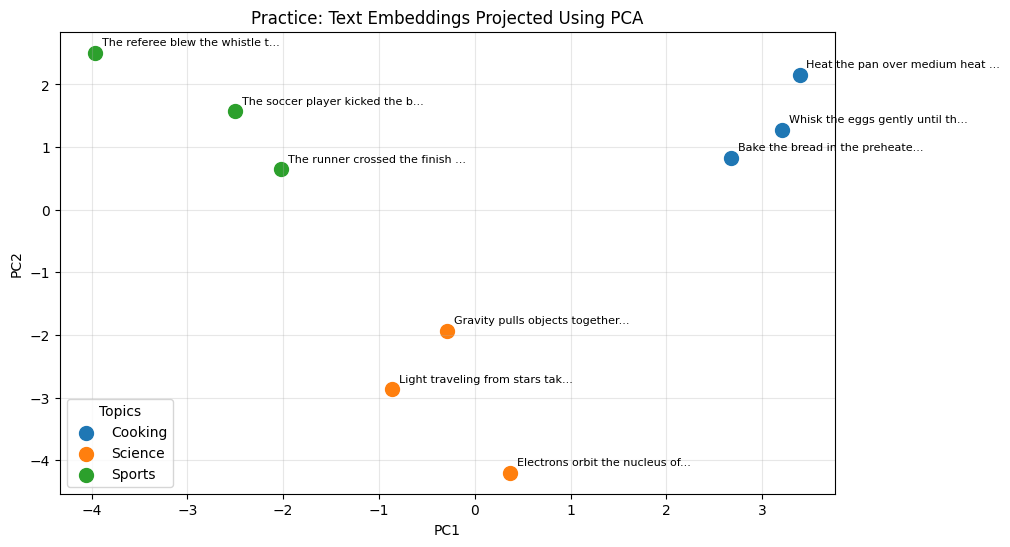

In [6]:
# PCA Projection: Compress 384 dimensions down to 2 dimensions for visualization
practice_pca = PCA(n_components=2)
practice_coords = practice_pca.fit_transform(practice_embeddings)

practice_df['PC1'] = practice_coords[:, 0]
practice_df['PC2'] = practice_coords[:, 1]

# 5. Plot the result to see if topics naturally cluster
fig, ax = plt.subplots(figsize=(10, 6))
for topic, group in practice_df.groupby('topic'):
    ax.scatter(group.PC1, group.PC2, label=topic, s=100)
    for _, r in group.iterrows():
        ax.annotate(r.sentence[:30] + "...", (r.PC1, r.PC2), xytext=(5, 5), textcoords='offset points', fontsize=8)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Practice: Text Embeddings Projected Using PCA')
ax.legend(title='Topics')
ax.grid(True, alpha=0.3)
plt.show()

# ESM_2 Protein Embedding
#Visualizing protein embeddings with ESM-2

**Question:** Do proteins from the same annotated family tend to have similar representations in a pretrained protein language model?

**Pipeline:** protein sequences → **ESM-2** → one embedding per protein (320 dimensions) → PCA projection (2D) → inspect points colored by known family.

> Important: ESM-2 generates embeddings; PCA and TensorFlow Embedding Projector visualize projections. The labels come from our curated examples, **not** from ESM-2 predictions.

Run cells in order. Internet is required to download the protein sequences and pretrained ESM-2 weights. CPU is sufficient for this small demonstration. No model training is required.

## 1. Install packages and select model
We use the relatively small pretrained `facebook/esm2_t6_8M_UR50D` (6 layers; 320-dimensional representations). Larger ESM-2 models take more memory.

Installs the Python packages the protein section needs. On Colab this runs once per session; if the cells above already ran, most packages are present and this is quick.

In [7]:
%pip -q install transformers torch scikit-learn matplotlib pandas requests

Re-imports the libraries for the protein section and prints the PyTorch version and whether a GPU is available. CPU is fine for this small demo.

In [8]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModel
print("PyTorch:",torch.__version__)
print("GPU available:",torch.cuda.is_available())

PyTorch: 2.11.0+cu130
GPU available: True


## 2. Load real proteins from UniProt
We compare three **annotated** groups. The accession numbers identify real reference sequences; verify the protein names printed below. A few proteins in one group may be relatively divergent, and small groups are not representative of all members.

If a protein cannot be retrieved, the notebook skips it and reports the problem. Retrieval requires internet.

1. Lists **9 real proteins** from three families (Globin, Cytochrome c, Lysozyme), each given by its UniProt accession.
2. `get_fasta()` downloads each sequence from UniProt and sanity-checks that the response is really a protein FASTA.
3. Builds a table of the proteins that downloaded, skips and reports any that fail, and stops early if too few came back. **Requires internet.**

In [9]:
examples = [
    ("Globin", "P69905"),  # human hemoglobin alpha
    ("Globin", "P68871"),  # human hemoglobin beta
    ("Globin", "P02144"),  # human myoglobin
    ("Globin", "P01942"),  # mouse hemoglobin alpha
    ("Cytochrome c", "P99999"),  # human
    ("Cytochrome c", "P00004"),  # horse
    ("Cytochrome c", "P00044"),  # yeast
    ("Lysozyme", "P61626"),  # human lysozyme C
    ("Lysozyme", "P00698"),  # chicken lysozyme C
]

def get_fasta(accession):
    url=f"https://rest.uniprot.org/uniprotkb/{accession}.fasta"
    r=requests.get(url,timeout=30); r.raise_for_status()
    lines=r.text.strip().splitlines()
    if not lines or not lines[0].startswith('>'):
        raise ValueError('Not a FASTA response')
    seq=''.join(lines[1:]).upper()
    if not seq or any(aa not in 'ACDEFGHIKLMNPQRSTVWYXUBZO' for aa in seq):
        raise ValueError('Unexpected protein letters')
    return lines[0][1:],seq

records=[]
for group,acc in examples:
    try:
        header,seq=get_fasta(acc)
        records.append(dict(family=group,accession=acc,name=header[:85],sequence=seq,length=len(seq)))
    except Exception as e:
        print('Skipped',acc,':',str(e))
df=pd.DataFrame(records)
if len(df)<4 or df.family.nunique()<2:
    raise RuntimeError('Not enough proteins could be downloaded; check internet or the UniProt service.')
display(df[['family','accession','name','length']])

,family,accession,name,length
0,Globin,P69905,sp|P69905|HBA_HUMAN Hemoglobin subunit alpha O...,142
1,Globin,P68871,sp|P68871|HBB_HUMAN Hemoglobin subunit beta OS...,147
2,Globin,P02144,sp|P02144|MYG_HUMAN Myoglobin OS=Homo sapiens ...,154
3,Globin,P01942,sp|P01942|HBA_MOUSE Hemoglobin subunit alpha O...,142
4,Cytochrome c,P99999,sp|P99999|CYC_HUMAN Cytochrome c OS=Homo sapie...,105
5,Cytochrome c,P00004,sp|P00004|CYC_HORSE Cytochrome c OS=Equus caba...,105
6,Cytochrome c,P00044,sp|P00044|CYC1_YEAST Cytochrome c isoform 1 OS...,109
7,Lysozyme,P61626,sp|P61626|LYSC_HUMAN Lysozyme C OS=Homo sapien...,148
8,Lysozyme,P00698,sp|P00698|LYSC_CHICK Lysozyme C OS=Gallus gall...,147


## 3. Extract ESM-2 embeddings (no training)
Each amino acid produces a contextual hidden-state vector. To represent a **whole protein**, we average the last-layer residue vectors, excluding special/padding tokens. This is called **mean pooling**. Different layers or pooling methods can yield different results.


1. Loads the small pretrained **protein** language model **ESM-2** (`esm2_t6_8M_UR50D`) and its tokenizer, moving it to GPU if one exists.
2. For each protein: tokenize the sequence → run the model (inference only) → **mean-pool** the per-residue vectors (excluding the special start/end tokens) into one 320-d protein embedding.
3. Stacks them into a `(proteins × 320)` matrix and asserts the shape is correct.

In [10]:
model_name='facebook/esm2_t6_8M_UR50D'
tokenizer=AutoTokenizer.from_pretrained(model_name)
model=AutoModel.from_pretrained(model_name)
model.eval()
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

vectors=[]
for record in records:
    seq=record['sequence']
    # Each sequence here is comfortably below the typical 1022-residue ESM-2 limit.
    if len(seq)>1022:
        raise ValueError(f"Sequence {record['accession']} exceeds the demo's length limit")
    batch=tokenizer(seq,return_tensors='pt',add_special_tokens=True)
    batch={name:value.to(device) for name,value in batch.items()}
    with torch.inference_mode():
        hidden=model(**batch).last_hidden_state[0]
    # ESM-2 adds beginning/end tokens; the internal positions represent amino acids.
    protein_embedding=hidden[1:1+len(seq)].mean(dim=0).cpu().numpy()
    vectors.append(protein_embedding)
embeddings=np.vstack(vectors)
print('Embeddings shape (proteins × dimensions):',embeddings.shape)
assert embeddings.shape==(len(records),320)

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 31.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Embeddings shape (proteins × dimensions): (9, 320)


In [13]:
# Take an example protein from our dataset
sample_protein = records[0]
sample_vector = embeddings[0]

print(f"Protein Name: {sample_protein['name']}")
print(f"Accession: {sample_protein['accession']}")
print(f"Sequence length: {sample_protein['length']} amino acids")
print(f"Embedding size: {sample_vector.shape[0]} dimensions (ESM-2 representation)")
print("\nFirst 15 dimensions of the protein embedding:")
print(sample_vector[:15])
print(f"\n... ({len(sample_vector) - 15} more dimensions representing this protein's structural & functional characteristics) ...")

Protein Name: sp|P69905|HBA_HUMAN Hemoglobin subunit alpha OS=Homo sapiens OX=9606 GN=HBA1 PE=1 SV=
Accession: P69905
Sequence length: 142 amino acids
Embedding size: 320 dimensions (ESM-2 representation)

First 15 dimensions of the protein embedding:
[-2.36470640e-01  3.30584012e-02  5.27745821e-02 -8.23498517e-03
  5.37217222e-02  4.61578742e-03 -6.52444214e-05 -1.36423439e-01
 -2.99947262e-01 -9.31152105e-02 -3.12885344e-02  2.26292815e-02
  7.77795389e-02  1.09522484e-01  1.63754851e-01]

... (305 more dimensions representing this protein's structural & functional characteristics) ...


## 4. Visualize the 2D projection
PCA compresses the 320-dimensional embedding vectors into two coordinates. **The axes are principal components, not interpretable biological features.** Distances in a projection can differ from distances in the full embedding space.

Projects the 320-d protein embeddings down to 2-D with PCA and plots them, colored by annotated family and labeled by accession. The axis labels report how much variance each principal component captures. Points that sit close together have similar ESM-2 representations.

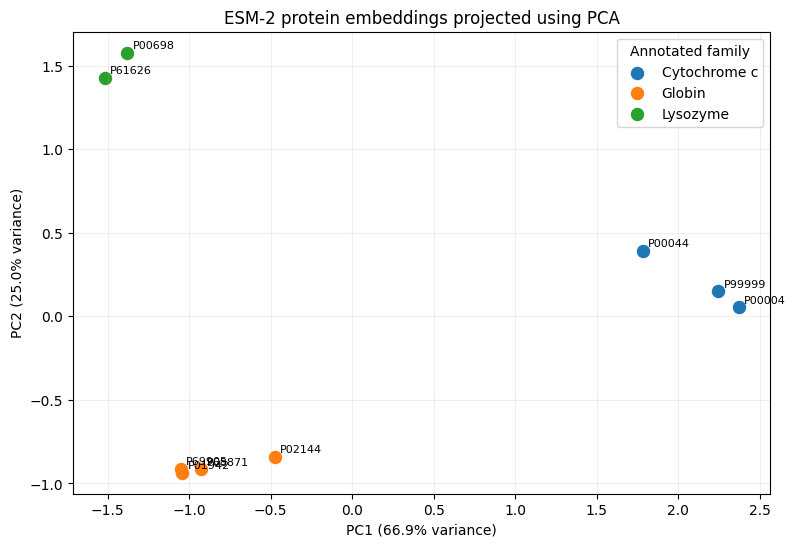

In [11]:
pca=PCA(n_components=2)
coords=pca.fit_transform(embeddings)
df['PC1']=coords[:,0]; df['PC2']=coords[:,1]
fig,ax=plt.subplots(figsize=(9,6))
for family,group in df.groupby('family'):
    ax.scatter(group.PC1,group.PC2,label=family,s=75)
    for _,r in group.iterrows():
        ax.annotate(r.accession,(r.PC1,r.PC2),xytext=(4,3),textcoords='offset points',fontsize=8)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)',
       title='ESM-2 protein embeddings projected using PCA')
ax.legend(title='Annotated family'); ax.grid(alpha=0.2); plt.show()

## 5. Export embeddings to TensorFlow Embedding Projector
The website accepts vectors and metadata. **Upload the original 320-dimensional vectors**, not the PCA coordinates; the Projector will perform its own 2D/3D projection.

1. Run the next cell.
2. Download `esm2_vectors.tsv` and `esm2_metadata.tsv` from the Colab Files panel.
3. Open https://projector.tensorflow.org/ and use **Load data** to import the vectors and metadata.


Saves two files for the **TensorFlow Embedding Projector**: `esm2_vectors.tsv` (the full 320-d vectors — *not* the PCA coordinates) and `esm2_metadata.tsv` (accession, family, name). Upload both at projector.tensorflow.org to explore the embeddings interactively.

In [12]:
np.savetxt('esm2_vectors.tsv',embeddings,delimiter='\t',fmt='%.8f')
df[['accession','family','name']].to_csv('esm2_metadata.tsv',sep='\t',index=False)
print('Saved esm2_vectors.tsv and esm2_metadata.tsv')
print('Each vector has',embeddings.shape[1],'dimensions.')

Saved esm2_vectors.tsv and esm2_metadata.tsv
Each vector has 320 dimensions.


- Embeddings are produced by a **pretrained** model. The activity performs **inference**, not training.
- Labels are external annotations used for coloring. PCA is unsupervised.
- Same-family grouping can reflect sequence similarity, taxonomic sampling, length, or other properties; it does not by itself demonstrate functional understanding or generalization.
- If comparing protein embeddings for downstream biological inference, control for homology and train/test leakage.
- For class use, pick short sequences to keep CPU runtime manageable.